## 1. Project Overview & Objectives
### Core Purpose: 
#### Integrates air quality, weather, and spatial data across Indian cities to analyze pollution patterns, weather impacts, and early warning indicators

### .Key Objectives:
#### 1.Hotspot Identification: Map and compare particulate matter ($PM_{2.5}$, $PM_{10}$) levels across geographic regions and cities.
#### 2.Meteorological Correlation: Quantify how atmospheric conditions (wind, humidity, temperature) affect pollutant dispersion.
#### 3.Predictive Foundation: Engineer time-series features to support forecasting and municipal health advisories.

### Data Sources:
#### Combines city metadata (cities.csv), daily air quality logs (air_quality_daily.csv), and meteorological records (weather_daily.csv).

## 2.LOAD DATASETS

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Load datasets
cities_df = pd.read_csv('cities.csv')
aq_df = pd.read_csv('air_quality_daily.csv')
weather_df = pd.read_csv('weather_daily.csv')

# Inspect basic info
print("--- Cities Dataset ---")
display(cities_df.head(3))
print("\n--- Air Quality Dataset Shape:", aq_df.shape)
print("--- Weather Dataset Shape:", weather_df.shape)

--- Cities Dataset ---


,city,state,region,latitude,longitude,elevation_m
0,Delhi,Delhi,North,28.6139,77.2090,214.0
1,Mumbai,Maharashtra,West,19.0760,72.8777,6.0
2,Kolkata,West Bengal,East,22.5726,88.3639,12.0



--- Air Quality Dataset Shape: (77150, 19)
--- Weather Dataset Shape: (124500, 14)


## 3. DATA CLEANING & PREPROCESSING

In [2]:
# Convert date columns to datetime
aq_df['date'] = pd.to_datetime(aq_df['date'])
weather_df['date'] = pd.to_datetime(weather_df['date'])

# Merge air quality and weather daily data
merged_df = pd.merge(aq_df, weather_df, on=['date', 'city'], how='inner')

# Merge with city metadata (region, state, coordinates, elevation)
merged_df = pd.merge(merged_df, cities_df, on='city', how='left')

# Extract temporal features
merged_df['year'] = merged_df['date'].dt.year
merged_df['month'] = merged_df['date'].dt.month
merged_df['day_of_week'] = merged_df['date'].dt.day_name()

print(f"Final Integrated Dataset Shape: {merged_df.shape}")
display(merged_df.head(2))

Final Integrated Dataset Shape: (77150, 39)


,date,city,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,...,et0_fao_evapotranspiration,weather_code,state,region,latitude,longitude,elevation_m,year,month,day_of_week
0,2022-08-05,Agartala,14.09,19.1,20.50,27.6,20.63,2.32,72.0,204.75,...,4.63,63,Tripura,Northeast,23.8315,91.2868,12.0,2022,8,Friday
1,2022-08-06,Agartala,12.12,19.3,17.44,27.7,23.11,1.10,48.0,208.00,...,3.89,63,Tripura,Northeast,23.8315,91.2868,12.0,2022,8,Saturday


## 4. EXPLORATORY DATA ANALYSIS (EDA)

Average Pollution by Region:


,region,india_aqi,pm2_5_mean
0,Central,138.655995,36.983246
1,East,171.759235,49.119919
2,North,179.577730,46.480698
3,Northeast,125.126377,26.929360
4,South,115.896555,22.870990
5,West,129.756597,31.044822


C:\Users\HP\AppData\Local\Temp\ipykernel_10084\1181647783.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_polluted_cities, x='india_aqi', y='city', palette='Reds_r')


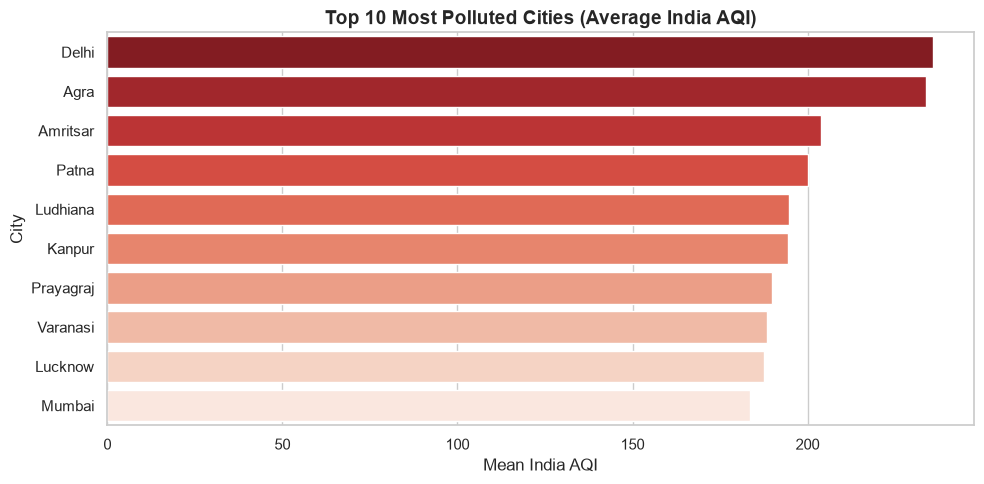

In [3]:
# Calculate average AQI and PM2.5 by region
region_summary = merged_df.groupby('region')[['india_aqi', 'pm2_5_mean']].mean().reset_index()
print("Average Pollution by Region:")
display(region_summary)

# Top 10 Most Polluted Cities by Mean India AQI
top_polluted_cities = merged_df.groupby('city')['india_aqi'].mean().reset_index()
top_polluted_cities = top_polluted_cities.sort_values(by='india_aqi', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_polluted_cities, x='india_aqi', y='city', palette='Reds_r')
plt.title('Top 10 Most Polluted Cities (Average India AQI)', fontsize=14, fontweight='bold')
plt.xlabel('Mean India AQI')
plt.ylabel('City')
plt.tight_layout()
plt.show()

## 5.VISUALIZATIONS

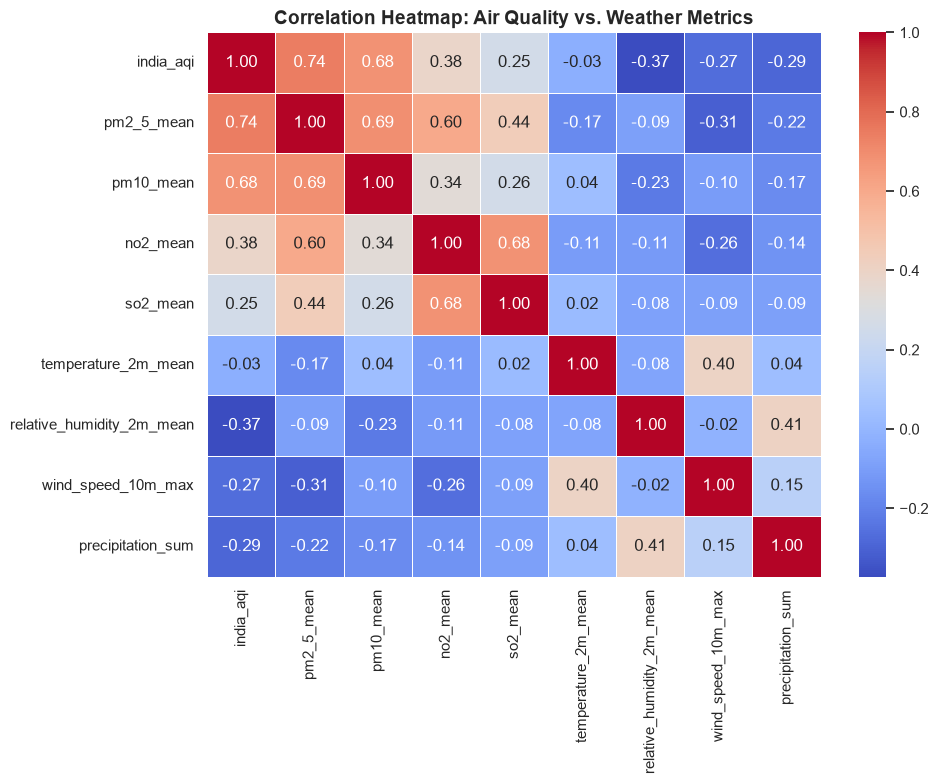

In [4]:
# Select numerical columns for correlation
corr_cols = ['india_aqi', 'pm2_5_mean', 'pm10_mean', 'no2_mean', 'so2_mean', 
             'temperature_2m_mean', 'relative_humidity_2m_mean', 
             'wind_speed_10m_max', 'precipitation_sum']

corr_matrix = merged_df[corr_cols].corr()

# Plot Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap: Air Quality vs. Weather Metrics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

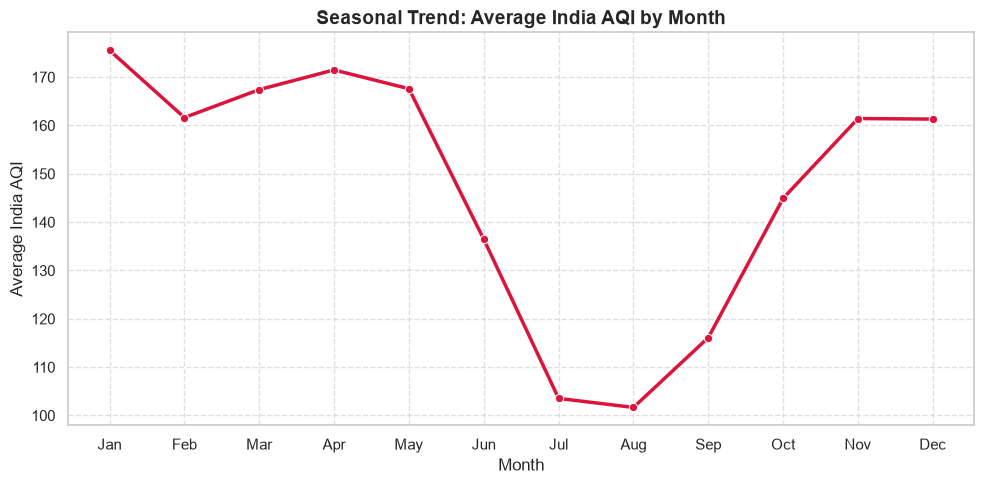

In [5]:
# Monthly average trends for India AQI
monthly_aqi = merged_df.groupby('month')['india_aqi'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_aqi, x='month', y='india_aqi', marker='o', color='crimson', linewidth=2.5)
plt.title('Seasonal Trend: Average India AQI by Month', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Average India AQI')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

R² Score: 0.8976
Mean Absolute Error (MAE): 14.79


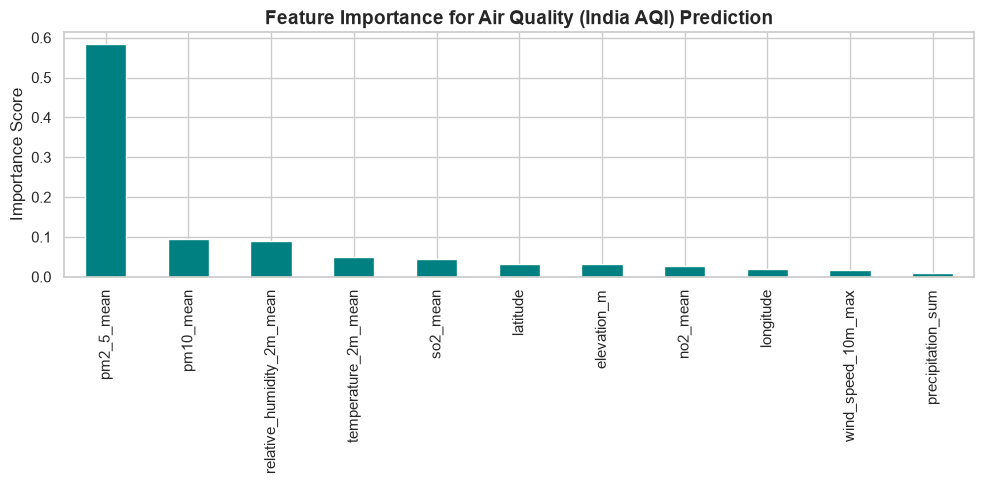

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Prepare features and target
features = ['pm2_5_mean', 'pm10_mean', 'no2_mean', 'so2_mean', 
            'temperature_2m_mean', 'relative_humidity_2m_mean', 
            'wind_speed_10m_max', 'precipitation_sum', 'elevation_m', 'latitude', 'longitude']

target = 'india_aqi'

# Drop missing values for modeling
model_df = merged_df[features + [target]].dropna()

X = model_df[features]
y = model_df[target]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Evaluate
y_pred = rf_model.predict(X_test)
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred):.2f}")

# Feature Importance Plot
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
importances.plot(kind='bar', color='teal')
plt.title('Feature Importance for Air Quality (India AQI) Prediction', fontsize=14, fontweight='bold')
plt.ylabel('Importance Score')
plt.tight_layout()
plt.show()

In [8]:
# Create lag and rolling window features for temporal forecasting
df_ts = merged_df.sort_values(by=['city', 'date']).copy()

# Add 1-day, 2-day, and 3-day AQI lag features per city
for lag in [1, 2, 3]:
    df_ts[f'aqi_lag_{lag}'] = df_ts.groupby('city')['india_aqi'].shift(lag)

# Add 7-day rolling mean of PM2.5 and AQI
df_ts['aqi_rolling_7d'] = df_ts.groupby('city')['india_aqi'].transform(lambda x: x.rolling(7, min_periods=1).mean())
df_ts['pm25_rolling_7d'] = df_ts.groupby('city')['pm2_5_mean'].transform(lambda x: x.rolling(7, min_periods=1).mean())

# Drop missing rows created by shifting
df_ts = df_ts.dropna(subset=['aqi_lag_1', 'aqi_lag_2', 'aqi_lag_3'])

print("Time-series lagged dataset ready:")
display(df_ts[['date', 'city', 'india_aqi', 'aqi_lag_1', 'aqi_rolling_7d']].head())

Time-series lagged dataset ready:


,date,city,india_aqi,aqi_lag_1,aqi_rolling_7d
3,2022-08-08,Agartala,65,75.0,65.000000
4,2022-08-09,Agartala,69,65.0,65.800000
5,2022-08-10,Agartala,61,69.0,65.000000
6,2022-08-11,Agartala,70,61.0,65.714286
7,2022-08-12,Agartala,83,70.0,67.285714


In [10]:
!pip install folium


   -------------------- ------------------- 1/2 [folium]
   -------------------- ------------------- 1/2 [folium]
   -------------------- ------------------- 1/2 [folium]
   -------------------- ------------------- 1/2 [folium]
   ---------------------------------------- 2/2 [folium]



In [11]:
import folium
from folium.plugins import HeatMap

# Filter latest available date in dataset
latest_date = merged_df['date'].max()
latest_data = merged_df[merged_df['date'] == latest_date].dropna(subset=['latitude', 'longitude', 'india_aqi'])

# Center map on India
m = folium.Map(location=[20.5937, 78.9629], zoom_start=5, tiles='CartoDB positron')

# Add heat map layer for AQI intensity
heat_data = [[row['latitude'], row['longitude'], row['india_aqi']] for idx, row in latest_data.iterrows()]
HeatMap(heat_data, radius=15, blur=10, max_zoom=1).add_to(m)

# Add city markers with AQI info
for _, row in latest_data.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=6,
        popup=f"<b>{row['city']}</b><br>AQI: {row['india_aqi']}<br>Category: {row['india_aqi_category']}",
        color='red' if row['india_aqi'] > 200 else 'green',
        fill=True,
        fill_opacity=0.7
    ).add_to(m)

# Display interactive map in Jupyter
m

In [12]:
def check_air_quality_alerts(df, city_name):
    city_df = df[df['city'] == city_name].sort_values(by='date', ascending=False)
    latest = city_df.iloc[0]
    
    print(f"=== AIR QUALITY INTELLIGENCE REPORT: {city_name.upper()} ({latest['date'].strftime('%Y-%m-%d')}) ===")
    print(f"Current AQI: {latest['india_aqi']} ({latest['india_aqi_category']})")
    print(f"Dominant Pollutant: {latest['dominant_pollutant']}")
    print(f"PM2.5: {latest['pm2_5_mean']} µg/m³ | Wind Speed: {latest['wind_speed_10m_max']} km/h")
    
    # Alert conditions
    alerts = []
    if latest['india_aqi'] > 300:
        alerts.append("SEVERE HEALTH HAZARD: Prolonged exposure may affect healthy people and seriously impact those with existing diseases.")
    elif latest['india_aqi'] > 200:
        alerts.append("POOR AIR QUALITY: High risk of respiratory discomfort to sensitive individuals.")
        
    if latest['wind_speed_10m_max'] < 8.0:
        alerts.append("STAGNANT WIND WARNING: Low atmospheric dispersion will cause pollutant accumulation.")
        
    if latest['precipitation_sum'] > 10.0:
        alerts.append("RAIN ADVISORY: Rainfall expected to wash down PM2.5/PM10 particulate matter.")
        
    print("\n--- ACTIVE ALERTS & ADVISORIES ---")
    if alerts:
        for alert in alerts:
            print(f"🚨 [ALERT] {alert}")
    else:
        print("✅ Air quality is within acceptable safety parameters.")

# Test alert system on Delhi
check_air_quality_alerts(merged_df, 'Delhi')

=== AIR QUALITY INTELLIGENCE REPORT: DELHI (2026-10-25) ===
Current AQI: 165 (Moderate)
Dominant Pollutant: O3
PM2.5: 46.9 µg/m³ | Wind Speed: 8.5 km/h

--- ACTIVE ALERTS & ADVISORIES ---
✅ Air quality is within acceptable safety parameters.


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Select features for forecasting
ml_features = [
    'pm2_5_mean', 'pm10_mean', 'no2_mean', 'so2_mean', 
    'temperature_2m_mean', 'relative_humidity_2m_mean', 
    'wind_speed_10m_max', 'precipitation_sum',
    'aqi_lag_1', 'aqi_lag_2', 'aqi_lag_3', 'aqi_rolling_7d'
]

target = 'india_aqi'

# Prepare clean dataset for modeling
ml_df = df_ts[ml_features + [target]].dropna()

X = ml_df[ml_features]
y = ml_df[target]

# Train / Test Split (Time-based split preserves temporal structure)
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Train Regressor
forecaster = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
forecaster.fit(X_train, y_train)

# Predictions & Evaluation
y_pred = forecaster.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"--- AIR QUALITY FORECASTING MODEL RESULTS ---")
print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

--- AIR QUALITY FORECASTING MODEL RESULTS ---
RMSE (Root Mean Squared Error): 23.41
R² Score: 0.8178


## # 6. Conclusion 

In [14]:
# Get the latest metrics for each city
latest_date = merged_df['date'].max()
summary_report = merged_df[merged_df['date'] == latest_date][[
    'city', 'state', 'region', 'india_aqi', 'india_aqi_category', 
    'pm2_5_mean', 'temperature_2m_mean', 'wind_speed_10m_max'
]].sort_values(by='india_aqi', ascending=False).reset_index(drop=True)

print(f"=== NATIONAL AIR QUALITY SUMMARY ({latest_date.strftime('%Y-%m-%d')}) ===")
display(summary_report.head(10))

# Export processed dataset for downstream applications (like Streamlit or PowerBI)
output_filename = 'environmental_intelligence_processed.csv'
merged_df.to_csv(output_filename, index=False)
print(f"\n✅ Successfully exported processed dataset to '{output_filename}'!")

=== NATIONAL AIR QUALITY SUMMARY (2026-10-25) ===


,city,state,region,india_aqi,india_aqi_category,pm2_5_mean,temperature_2m_mean,wind_speed_10m_max
0,Mumbai,Maharashtra,West,302,Very Poor,75.40,30.8,12.1
1,Visakhapatnam,Andhra Pradesh,South,267,Poor,77.20,28.2,14.0
2,Kolkata,West Bengal,East,247,Poor,55.20,27.0,10.8
3,Prayagraj,Uttar Pradesh,North,222,Poor,86.95,26.4,8.5
4,Lucknow,Uttar Pradesh,North,220,Poor,95.85,27.1,12.9
5,Agartala,Tripura,Northeast,215,Poor,48.95,27.8,7.7
6,Vadodara,Gujarat,West,206,Poor,42.40,29.8,6.8
7,Agra,Uttar Pradesh,North,206,Poor,80.55,26.9,17.3
8,Varanasi,Uttar Pradesh,North,200,Moderate,64.44,26.7,10.1
9,Ahmedabad,Gujarat,West,196,Moderate,39.30,30.9,8.5



✅ Successfully exported processed dataset to 'environmental_intelligence_processed.csv'!
